In [ ]:
!pip install meshio netCDF4
from google.colab import files
up = files.upload()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 30.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 73.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [meshio]


Saving thermal_input_out_mech0.e to thermal_input_out_mech0.e


In [ ]:
import time, numpy as np, torch, torch.nn as nn
import meshio
from netCDF4 import Dataset, chartostring

torch.set_default_dtype(torch.float64)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0); np.random.seed(0)

# problem parameters (SI, to match FEM)
L, H = 5.0, 0.3
E, nu, alpha = 50e3, 0.2, 1e-5
dT, T0 = 50.0, 298.0
HEATED_SIDE = "bottom" # "top" or "bottom" to  match FEM data
lam = E*nu/((1+nu)*(1-2*nu)); mu = E/(2*(1+nu))
S0 = E*alpha*dT  # stress scale
U0 = alpha*dT*H   # displacement scale

In [ ]:
#  networks
class MLP(nn.Module):
    def __init__(self, n_out, width=64, depth=5):
        super().__init__()
        layers, n_in = [], 2
        for _ in range(depth):
            layers += [nn.Linear(n_in, width), nn.Tanh()]; n_in = width
        layers += [nn.Linear(width, n_out)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x, y):
        return self.net(torch.cat([x/L, y/H], 1))

thetaNet = MLP(1).to(dev) # theta = (T - T0)/dT
uNet     = MLP(2).to(dev)

def theta_fn(x, y): return thetaNet(x, y)

def disp_fn(x, y):
    bubble = x*(L - x)/(L/2)**2 # hard clamp at x=0, x=L
    return U0*bubble*uNet(x, y) # (N,2): ux, uy

def grad(f, x):
    return torch.autograd.grad(f, x, torch.ones_like(f), create_graph=True)[0]

#  physics
def thermal_residual(x, y):
    th = theta_fn(x, y)
    th_x, th_y = grad(th, x), grad(th, y)
    return (grad(th_x, x) + grad(th_y, y))*H**2

def stress(x, y, freeze_T):
    u = disp_fn(x, y); ux, uy = u[:, :1], u[:, 1:]
    exx = grad(ux, x); eyy = grad(uy, y)
    exy = 0.5*(grad(ux, y) + grad(uy, x))
    th = theta_fn(x, y)
    if freeze_T: th = th.detach()
    dTh = dT*th
    tr = exx + eyy
    sxx = lam*tr + 2*mu*exx - alpha*(3*lam + 2*mu)*dTh
    syy = lam*tr + 2*mu*eyy - alpha*(3*lam + 2*mu)*dTh
    sxy = 2*mu*exy
    return sxx, syy, sxy

def mech_residual(x, y, freeze_T=True):
    sxx, syy, sxy = stress(x, y, freeze_T)
    r1 = grad(sxx, x) + grad(sxy, y)
    r2 = grad(sxy, x) + grad(syy, y)
    return r1*H/S0, r2*H/S0

#  sampling
def P(n, lo_x, hi_x, lo_y, hi_y):
    x = (lo_x + (hi_x-lo_x)*torch.rand(n, 1)).to(dev).requires_grad_(True)
    y = (lo_y + (hi_y-lo_y)*torch.rand(n, 1)).to(dev).requires_grad_(True)
    return x, y

def sample(n_in=8000, n_bc=400, eps=1e-6):
    d = {"int": P(n_in, 0, L, 0, H)}
    d["left"]   = P(n_bc, 0, 0, eps, H-eps)
    d["right"]  = P(n_bc, L, L, eps, H-eps)
    d["bottom"] = P(n_bc, eps, L-eps, 0, 0)
    d["top"]    = P(n_bc, eps, L-eps, H, H)
    return d

def load_fem(path, nx=100, ny=10):
    ds = Dataset(path)
    names = [str(s).strip() for s in chartostring(ds["name_nod_var"][:])]
    X, Y = np.array(ds["coordx"][:]), np.array(ds["coordy"][:])
    nsteps = ds["time_whole"].shape[0]
    print("variables:", names, "| time steps:", nsteps)
    data = {}
    for i, n in enumerate(names):
        arr = np.array(ds[f"vals_nod_var{i+1}"][:]) # (steps, nodes)
        print(f"  {n}: max|.| per step =", np.abs(arr).max(axis=1))
        data[n] = arr[-1] # last step
    ix, iy = X/(L/nx), Y/(H/ny)
    vert = (np.abs(ix-np.round(ix)) < 1e-6) & (np.abs(iy-np.round(iy)) < 1e-6)
    t = lambda a: torch.tensor(a).reshape(-1, 1).to(dev)
    fem = {"x": t(X), "y": t(Y), "ux": t(data["disp_x"]), "uy": t(data["disp_y"]),
           "T": t(data["T"]), "vert": torch.tensor(vert).to(dev)}
    print("max |ux|, |uy| (last step):", fem["ux"].abs().max().item(), fem["uy"].abs().max().item())
    return fem

#  losses
def thermal_loss(d, w_bc=10.0):
    x, y = d["int"]
    l_pde = thermal_residual(x, y).pow(2).mean()
    target = {"left": 0., "right": 0.,
              "top": 1. if HEATED_SIDE == "top" else 0.,
              "bottom": 1. if HEATED_SIDE == "bottom" else 0.}
    l_bc = sum((theta_fn(*d[k]) - v).pow(2).mean() for k, v in target.items())
    return l_pde + w_bc*l_bc

def mech_loss(d, w_tr=10.0, freeze_T=True):
    x, y = d["int"]
    r1, r2 = mech_residual(x, y, freeze_T)
    l_pde = r1.pow(2).mean() + r2.pow(2).mean()
    l_tr = 0.
    for k in ["top", "bottom"]:                 # traction-free: syy = sxy = 0
        xb, yb = d[k]
        _, syy, sxy = stress(xb, yb, freeze_T)
        l_tr = l_tr + (syy/S0).pow(2).mean() + (sxy/S0).pow(2).mean()
    return l_pde + w_tr*l_tr

def data_loss_T(fem):
    v = fem["vert"]
    return (theta_fn(fem["x"][v].reshape(-1,1), fem["y"][v].reshape(-1,1))
            - (fem["T"][v].reshape(-1,1)-T0)/dT).pow(2).mean()

def data_loss_u(fem):
    u = disp_fn(fem["x"], fem["y"])
    return ((u[:, :1]-fem["ux"])/U0).pow(2).mean() + ((u[:, 1:]-fem["uy"])/U0).pow(2).mean()

hist = {}

# training
def train(params, loss_fn, n_adam=10000, n_lbfgs=500, resample_every=500, tag=""):
    t0 = time.time()
    h_adam, h_lb = [], []
    opt = torch.optim.Adam(params, lr=1e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.9995)
    d = sample()
    for it in range(n_adam):
        if it % resample_every == 0: d = sample()
        opt.zero_grad(); loss = loss_fn(d); loss.backward(); opt.step(); sched.step()
        h_adam.append(loss.item())
        if it % 1000 == 0: print(f"[{tag}] Adam {it:6d}  loss {loss.item():.3e}")
    d = sample(n_in=15000)
    lb = torch.optim.LBFGS(params, lr=1.0, max_iter=n_lbfgs, history_size=50,
                           tolerance_grad=1e-12, tolerance_change=1e-14,
                           line_search_fn="strong_wolfe")
    def closure():
        lb.zero_grad(); l = loss_fn(d); l.backward()
        h_lb.append(l.item()); return l
    lb.step(closure)
    t = time.time() - t0
    hist[tag] = {"adam": np.array(h_adam), "lbfgs": np.array(h_lb), "time": t}
    print(f"[{tag}] final loss {loss_fn(d).item():.3e} | time {t:.1f}s "
          f"| L-BFGS function evals: {len(h_lb)}")

def run(fem_train=None, fem_test=None, joint=False):
    # Stage 1: thermal
    lT = (lambda d: thermal_loss(d) + (data_loss_T(fem_train) if fem_train else 0.))
    train(list(thetaNet.parameters()), lT, tag="thermal")
    # Stage 2: mechanical (T frozen = weak coupling)
    for p in thetaNet.parameters(): p.requires_grad_(joint)
    params = list(uNet.parameters()) + (list(thetaNet.parameters()) if joint else [])
    lM = (lambda d: mech_loss(d, freeze_T=not joint) + (data_loss_u(fem_train) if fem_train else 0.))
    train(params, lM, tag="mechanical")
    if fem_test: evaluate(fem_test)

#  evaluation vs FEM
def rel_l2(a, b): return (torch.norm(a-b)/torch.norm(b)).item()

def evaluate(fem):
    x, y = fem["x"].clone().requires_grad_(True), fem["y"].clone().requires_grad_(True)
    T = T0 + dT*theta_fn(x, y)
    u = disp_fn(x, y); v = fem["vert"]
    print(f"Rel. L2 error  T: {rel_l2(T[v], fem['T'][v]):.3e}  "
          f"ux: {rel_l2(u[:, :1], fem['ux']):.3e}  uy: {rel_l2(u[:, 1:], fem['uy']):.3e}")


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

def evaluate(fem):
    x, y = fem["x"], fem["y"]
    v = fem["vert"]
    with torch.no_grad():
        dTp = dT*theta_fn(x, y) # predicted rise
        u = disp_fn(x, y)
    dTf = fem["T"] - T0
    print(f"Rel. L2 error  dT: {rel_l2(dTp[v], dTf[v]):.3e}  "
          f"ux: {rel_l2(u[:, :1], fem['ux']):.3e}  uy: {rel_l2(u[:, 1:], fem['uy']):.3e}")

def plot_fields(fem, nxp=400, nyp=40):
    xg = torch.linspace(0, L, nxp, dtype=torch.float64)
    yg = torch.linspace(0, H, nyp, dtype=torch.float64)
    XX, YY = torch.meshgrid(xg, yg, indexing="ij")
    xs, ys = XX.reshape(-1, 1).to(dev), YY.reshape(-1, 1).to(dev)
    with torch.no_grad():
        Tp = (T0 + dT*theta_fn(xs, ys)).cpu().numpy().reshape(nxp, nyp)
        up = disp_fn(xs, ys).cpu().numpy()
    uxp, uyp = up[:, 0].reshape(nxp, nyp), up[:, 1].reshape(nxp, nyp)
    Xn, Yn = XX.numpy(), YY.numpy()

    # FEM on its own nodes
    fx, fy = fem["x"].cpu().numpy().ravel(), fem["y"].cpu().numpy().ravel()
    v = fem["vert"].cpu().numpy()
    tri_all = mtri.Triangulation(fx, fy)
    tri_v = mtri.Triangulation(fx[v], fy[v])
    # PINN at FEM nodes for the error maps
    with torch.no_grad():
        Tn = (T0 + dT*theta_fn(fem["x"], fem["y"])).cpu().numpy().ravel()
        un = disp_fn(fem["x"], fem["y"]).cpu().numpy()

    rows = [("Temperature [K]", Tp, fem["T"].cpu().numpy().ravel(), Tn, tri_v, v),
            ("u_x [m]", uxp, fem["ux"].cpu().numpy().ravel(), un[:, 0], tri_all, None),
            ("u_y [m]", uyp, fem["uy"].cpu().numpy().ravel(), un[:, 1], tri_all, None)]
    fig, axs = plt.subplots(3, 3, figsize=(16, 7))
    for r, (name, pg, fem_f, pinn_n, tri, mask) in enumerate(rows):
        f = fem_f[mask] if mask is not None else fem_f
        p = pinn_n[mask] if mask is not None else pinn_n
        vmin, vmax = f.min(), f.max()
        if vmax - vmin < 1e-30: vmax = vmin + 1e-30      # avoid degenerate levels
        lv = np.linspace(vmin, vmax, 30)
        c0 = axs[r, 0].contourf(Xn, Yn, pg, levels=lv, extend="both")
        c1 = axs[r, 1].tricontourf(tri, f, levels=lv, extend="both")
        c2 = axs[r, 2].tricontourf(tri, np.abs(p - f), levels=30)
        for ax, c, t in zip(axs[r], [c0, c1, c2], ["PINN", "FEM", "|error|"]):
            ax.set_title(f"{name}: {t}"); ax.set_aspect("auto"); plt.colorbar(c, ax=ax)
    plt.tight_layout(); plt.show()


variables: ['T', 'disp_x', 'disp_y'] | time steps: 2
  T: max|.| per step = [348. 348.]
  disp_x: max|.| per step = [0.00000000e+00 3.59452139e-05]
  disp_y: max|.| per step = [0.         0.00017977]
max |ux|, |uy| (last step): 3.594521388888294e-05 0.000179773409359253


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


[thermal] Adam      0  loss 1.688e+01
[thermal] Adam   1000  loss 7.902e-01
[thermal] Adam   2000  loss 2.911e-01
[thermal] Adam   3000  loss 1.960e-01
[thermal] Adam   4000  loss 1.830e-01
[thermal] Adam   5000  loss 1.863e-01
[thermal] Adam   6000  loss 1.083e-01
[thermal] Adam   7000  loss 1.080e-01
[thermal] Adam   8000  loss 1.188e-01
[thermal] Adam   9000  loss 9.256e-02
[thermal] final loss 3.544e-02 | time 128.6s | L-BFGS function evals: 536
[mechanical] Adam      0  loss 2.928e+01
[mechanical] Adam   1000  loss 2.593e+00
[mechanical] Adam   2000  loss 2.497e+00
[mechanical] Adam   3000  loss 2.507e+00
[mechanical] Adam   4000  loss 2.430e+00
[mechanical] Adam   5000  loss 2.430e+00
[mechanical] Adam   6000  loss 2.557e+00
[mechanical] Adam   7000  loss 2.460e+00
[mechanical] Adam   8000  loss 2.506e+00
[mechanical] Adam   9000  loss 2.366e+00
[mechanical] final loss 2.229e+00 | time 400.8s | L-BFGS function evals: 532
Rel. L2 error  dT: 1.904e-02  ux: 1.021e+01  uy: 1.343e+00


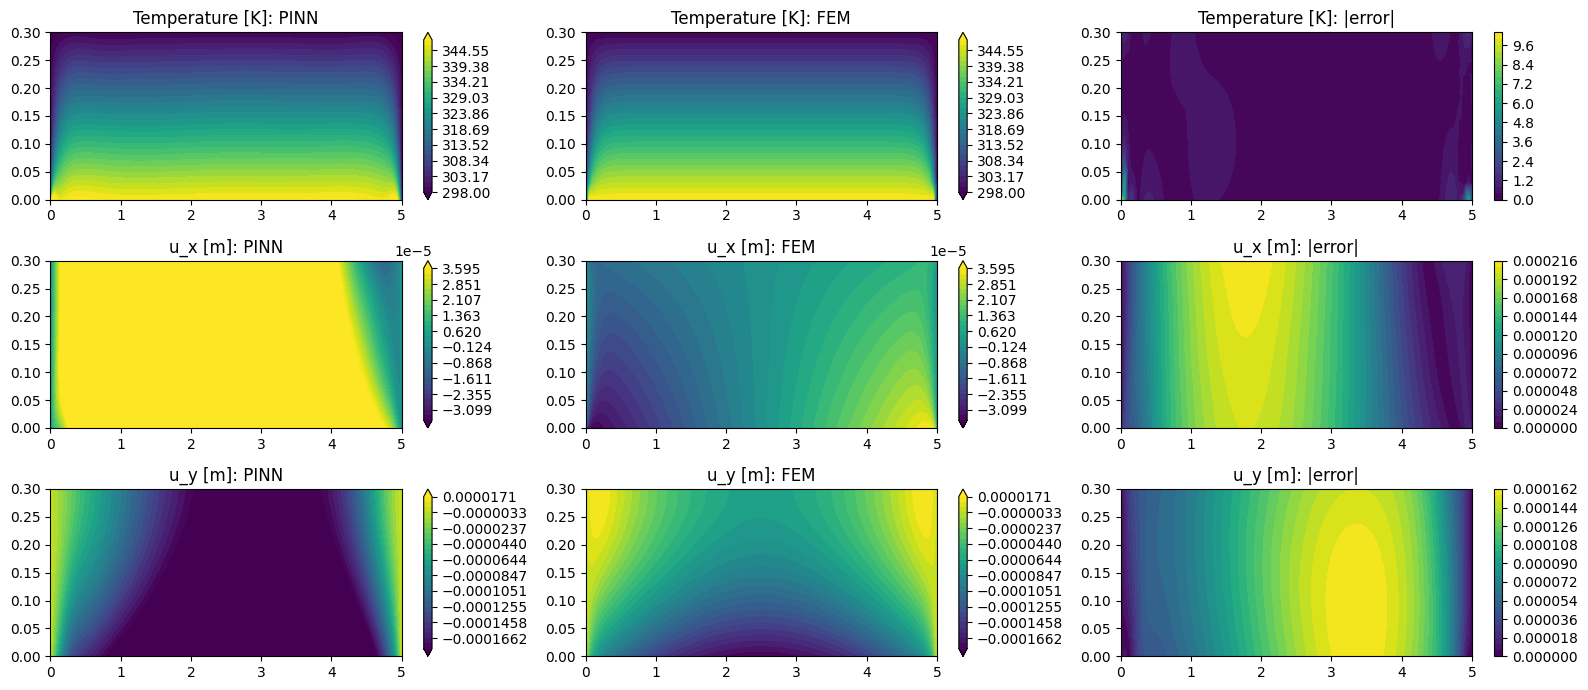

In [ ]:
if __name__ == "__main__":
    fem = load_fem("thermal_input_out_mech0.e")
    run(fem_train=None, fem_test=fem)
    plot_fields(fem)

In [ ]:
import copy
case1 = {"uNet": copy.deepcopy(uNet.state_dict()), "disp_fn": disp_fn}
torch.save(case1["uNet"], "case1_uNet.pt")
torch.save(thetaNet.state_dict(), "thetaNet.pt")   # shared thermal field

In [ ]:
UX0, UY0 = 5e-5, 2e-4 # output scales, order of the FEM magnitudes
SC = torch.tensor([UX0, UY0], device=dev)

uNet2 = MLP(2, width=64, depth=5).to(dev) # fresh network for the DEM case

def disp_fn_dem(x, y):
    bubble = x*(L - x)/(L/2)**2 # hard clamp at x = 0, L
    return bubble*uNet2(x, y)*SC

def energy_loss(x, y):
    u = disp_fn_dem(x, y); ux, uy = u[:, :1], u[:, 1:]
    exx, eyy = grad(ux, x), grad(uy, y)
    exy = 0.5*(grad(ux, y) + grad(uy, x))
    eth = alpha*dT*theta_fn(x, y).detach() # thermal strain from the frozen T field
    axx, ayy, azz = exx - eth, eyy - eth, -eth # plane strain: total e_zz = 0
    tr = axx + ayy + azz
    W = 0.5*lam*tr**2 + mu*(axx**2 + ayy**2 + azz**2 + 2*exy**2)
    return W.mean()/(E*(alpha*dT)**2)

def make_grid(nx=300, ny=30):
    xs = (torch.arange(nx, dtype=torch.float64) + 0.5)*L/nx
    ys = (torch.arange(ny, dtype=torch.float64) + 0.5)*H/ny
    X, Y = torch.meshgrid(xs, ys, indexing="ij")
    return (X.reshape(-1, 1).to(dev).requires_grad_(True),
            Y.reshape(-1, 1).to(dev).requires_grad_(True))

In [ ]:
for p in thetaNet.parameters(): p.requires_grad_(False) # T is frozen (weak coupling)
gx, gy = make_grid()
train(list(uNet2.parameters()), lambda d: energy_loss(gx, gy),
      n_adam=10000, n_lbfgs=1000, tag="mechanical-DEM")

[mechanical-DEM] Adam      0  loss 8.654e-01
[mechanical-DEM] Adam   1000  loss 4.009e-01
[mechanical-DEM] Adam   2000  loss 3.977e-01
[mechanical-DEM] Adam   3000  loss 3.971e-01
[mechanical-DEM] Adam   4000  loss 3.968e-01
[mechanical-DEM] Adam   5000  loss 3.966e-01
[mechanical-DEM] Adam   6000  loss 3.965e-01
[mechanical-DEM] Adam   7000  loss 3.965e-01
[mechanical-DEM] Adam   8000  loss 3.964e-01
[mechanical-DEM] Adam   9000  loss 3.964e-01
[mechanical-DEM] final loss 3.956e-01 | time 114.5s | L-BFGS function evals: 1055


Case 2 (DEM):
Rel. L2 error  dT: 1.904e-02  ux: 9.576e-02  uy: 3.887e-02


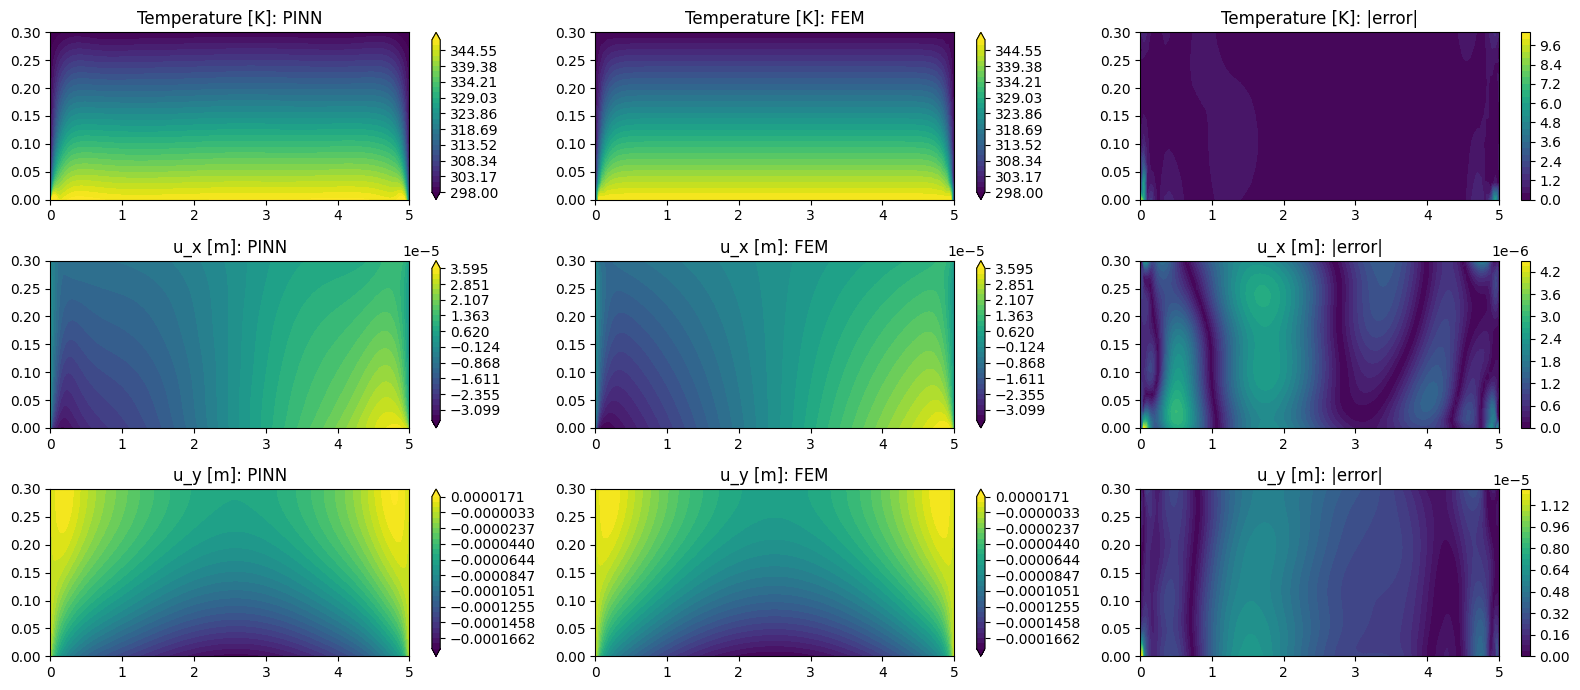

In [ ]:
disp_fn = disp_fn_dem
print("Case 2 (DEM):"); evaluate(fem); plot_fields(fem)
disp_fn = case1["disp_fn"] # restore Case 1

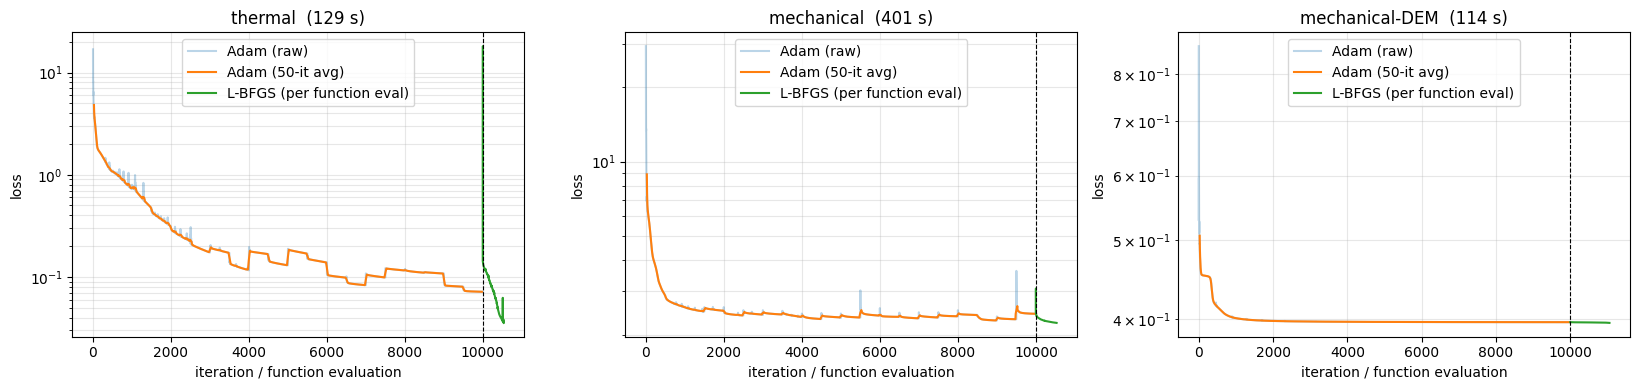

In [ ]:
def plot_loss_history(hist, tags=None, smooth=50):
    tags = tags or list(hist.keys())
    fig, axs = plt.subplots(1, len(tags), figsize=(5.5*len(tags), 4), squeeze=False)
    for ax, tag in zip(axs[0], tags):
        a, l = hist[tag]["adam"], hist[tag]["lbfgs"]
        ax.semilogy(np.arange(len(a)), a, alpha=0.3, label="Adam (raw)")
        if len(a) > smooth:
            sm = np.convolve(a, np.ones(smooth)/smooth, mode="valid")
            ax.semilogy(np.arange(len(sm)) + smooth//2, sm, label=f"Adam ({smooth}-it avg)")
        ax.semilogy(len(a) + np.arange(len(l)), l, label="L-BFGS (per function eval)")
        ax.axvline(len(a), color="k", ls="--", lw=0.8)
        ax.set_xlabel("iteration / function evaluation"); ax.set_ylabel("loss")
        ax.set_title(f"{tag}  ({hist[tag]['time']:.0f} s)")
        ax.grid(alpha=0.3, which="both"); ax.legend()
    plt.tight_layout(); plt.show()

plot_loss_history(hist) # thermal, mechanical (Case 1), mechanical-DEM